# 02 – Data Preparation
This notebook covers the Data Preparation phase (CRISP-DM):
1. Data cleaning
2. Data construction / feature engineering
3. Data selection
4. Data formatting (train/validation/test split)
5. Feature scaling

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")
FIG_DIR   = "../figures"
DATA_OUT  = "../data/processed"
MODEL_DIR = "../models"
os.makedirs(DATA_OUT, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

In [13]:
df = pd.read_csv("../data/Tetuan_City_power_consumption.csv")
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
df = df.rename(columns={
    "Wind Speed": "WindSpeed",
    "general diffuse flows": "GeneralDiffuseFlows",
    "diffuse flows": "DiffuseFlows",
    "Zone 1 Power Consumption": "Zone1",
    "Zone 2 Power Consumption": "Zone2",
    "Zone 3 Power Consumption": "Zone3",
})
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%m/%d/%Y %H:%M")
df = df.set_index("DateTime").sort_index()

WEATHER = ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]
TARGETS = ["Zone1", "Zone2", "Zone3"]
df.shape

(52416, 8)

## 1. Data Cleaning
The Data Understanding phase showed no missing values, no duplicates and no time gaps.
IQR outliers in diffuse flows and Zone 3 are real values (daytime solar radiation and summer
peaks), so they are kept. Removing them would hide exactly the peaks we want to predict.

In [14]:
assert df.isnull().sum().sum() == 0, "Missing values found!"
assert df.index.duplicated().sum() == 0, "Duplicate timestamps found!"
print("No missing values or duplicates - no imputation needed.")

No missing values or duplicates - no imputation needed.


## 2. Feature Engineering
### 2.1 Time features
EDA showed strong daily, weekly and seasonal patterns, so we extract them from the timestamp.

In [15]:
df["hour"]          = df.index.hour
df["minute_of_day"] = df.index.hour * 60 + df.index.minute
df["dayofweek"]     = df.index.dayofweek
df["month"]         = df.index.month
df["is_weekend"]    = (df["dayofweek"] >= 5).astype(int)

C:\Users\olsas\AppData\Local\Temp\ipykernel_11780\1806732913.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dayofweek"]     = df.index.dayofweek


### 2.2 Cyclical encoding (sin / cos)
Time is circular: 23:50 is close to 00:00, and December is close to January.
Plain numbers (0-23) would tell the model these are far apart, so we encode them with sine and cosine.

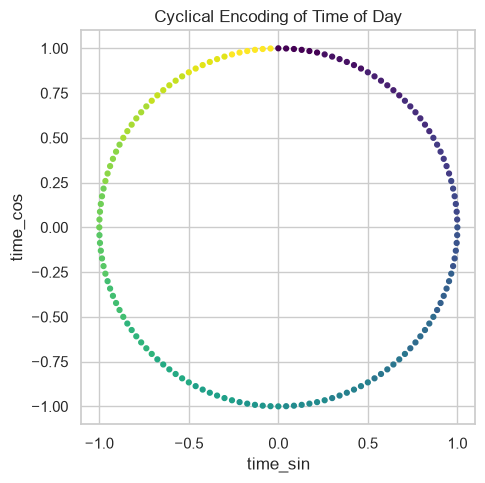

In [16]:
df["time_sin"]  = np.sin(2 * np.pi * df["minute_of_day"] / 1440)
df["time_cos"]  = np.cos(2 * np.pi * df["minute_of_day"] / 1440)
df["dow_sin"]   = np.sin(2 * np.pi * df["dayofweek"] / 7)
df["dow_cos"]   = np.cos(2 * np.pi * df["dayofweek"] / 7)
df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

# Visual proof: one day forms a circle
fig, ax = plt.subplots(figsize=(5, 5))
day1 = df.iloc[:144]
ax.scatter(day1["time_sin"], day1["time_cos"], c=day1["hour"], cmap="viridis", s=12)
ax.set_xlabel("time_sin"); ax.set_ylabel("time_cos")
ax.set_title("Cyclical Encoding of Time of Day")
ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/11_cyclical_encoding.png", dpi=150); plt.show()

### 2.3 Lag and rolling features
Past consumption is the best predictor of future consumption. For the classical / MLP models we add:
- lag1 = value 10 minutes ago
- lag6 = value 1 hour ago
- lag144 = value at the same time yesterday
- roll6 = average of the last hour

The LSTM/GRU models will instead receive a sequence (window) of past values.
`shift()` makes sure only past information is used, which avoids data leakage.

In [17]:
for z in TARGETS:
    df[f"{z}_lag1"]   = df[z].shift(1)
    df[f"{z}_lag6"]   = df[z].shift(6)
    df[f"{z}_lag144"] = df[z].shift(144)
    df[f"{z}_roll6"]  = df[z].shift(1).rolling(6).mean()

print("Rows before dropping NaN:", len(df))
df = df.dropna()          # first 144 rows (1 day) have no lag144 value
print("Rows after dropping NaN:", len(df))

Rows before dropping NaN: 52416
Rows after dropping NaN: 52272


## 3. Data Selection
- All 5 weather features are kept. Temperature and humidity correlate clearly with consumption,
  and diffuse flows carry daytime information.
- Raw helper columns (hour, minute_of_day, dayofweek, month) are replaced by their sin/cos versions.
- Two feature sets are defined: a tabular set (for baseline/MLP models) and a sequence set (for LSTM/GRU).

In [18]:
CYCLICAL = ["time_sin", "time_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend"]
LAGS     = [c for c in df.columns if "_lag" in c or "_roll" in c]

FEATURES_TABULAR = WEATHER + CYCLICAL + LAGS        # 24 features
FEATURES_SEQ     = WEATHER + CYCLICAL + TARGETS     # 15 features per time step

print("Tabular features:", len(FEATURES_TABULAR))
print("Sequence features:", len(FEATURES_SEQ))

Tabular features: 24
Sequence features: 15


## 4. Data Formatting – Chronological Split
This is time-series data, so it must NOT be shuffled. Shuffling would let the model "see the future".
Split: 70% train / 15% validation / 15% test, in time order.

Train        36590 rows   2017-01-02 00:00:00  ->  2017-09-13 02:10:00
Validation    7841 rows   2017-09-13 02:20:00  ->  2017-11-06 13:00:00
Test          7841 rows   2017-11-06 13:10:00  ->  2017-12-30 23:50:00


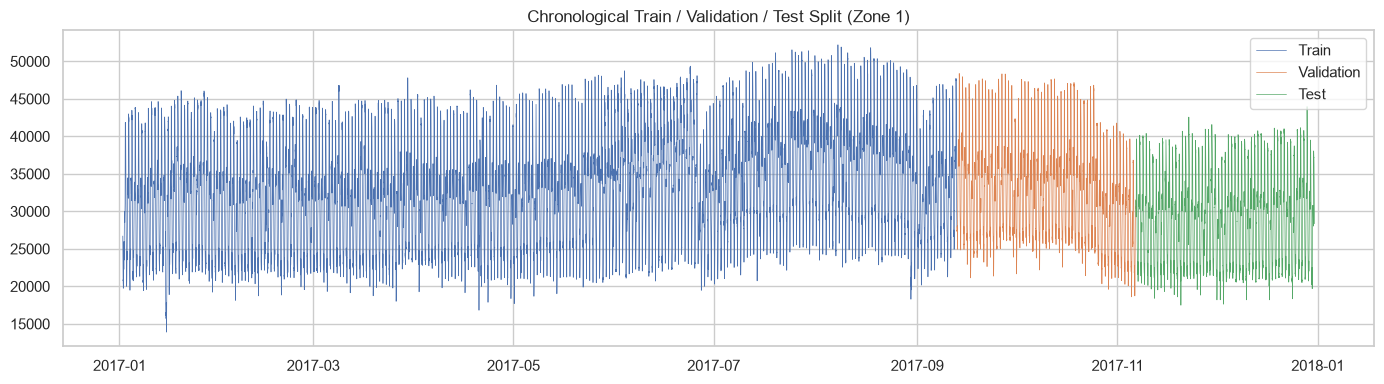

In [19]:
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(part):>6} rows   {part.index.min()}  ->  {part.index.max()}")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train.index, train["Zone1"], label="Train", lw=0.5)
ax.plot(val.index,   val["Zone1"],   label="Validation", lw=0.5)
ax.plot(test.index,  test["Zone1"],  label="Test", lw=0.5)
ax.set_title("Chronological Train / Validation / Test Split (Zone 1)")
ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/12_train_val_test_split.png", dpi=150); plt.show()

## 5. Feature Scaling
Neural networks train better when inputs are on the same scale (0-1).
The scalers are fitted on the TRAINING set only, then applied to validation and test.
This prevents data leakage. A separate scaler is used for the targets so predictions can be
converted back to KW later.

In [20]:
ALL_COLS     = sorted(set(FEATURES_TABULAR + FEATURES_SEQ + TARGETS), key=list(df.columns).index)
feature_cols = [c for c in ALL_COLS if c not in TARGETS]

feature_scaler = MinMaxScaler()
target_scaler  = MinMaxScaler()
feature_scaler.fit(train[feature_cols])     # fit on train only!
target_scaler.fit(train[TARGETS])

def scale(part):
    out = part[ALL_COLS].copy()
    out[feature_cols] = feature_scaler.transform(part[feature_cols])
    out[TARGETS]      = target_scaler.transform(part[TARGETS])
    return out

train_s, val_s, test_s = scale(train), scale(val), scale(test)
print("Train targets:\n", train_s[TARGETS].describe().loc[["min", "max"]])
print("\nTest targets:\n",  test_s[TARGETS].describe().loc[["min", "max"]])

Train targets:
      Zone1  Zone2  Zone3
min    0.0    0.0    0.0
max    1.0    1.0    1.0

Test targets:
         Zone1     Zone2     Zone3
min  0.093644  0.124052 -0.057215
max  0.785120  0.938401  0.451227


In [21]:
train_s.to_csv(f"{DATA_OUT}/train.csv")
val_s.to_csv(f"{DATA_OUT}/val.csv")
test_s.to_csv(f"{DATA_OUT}/test.csv")

joblib.dump(feature_scaler, f"{MODEL_DIR}/feature_scaler.pkl")
joblib.dump(target_scaler,  f"{MODEL_DIR}/target_scaler.pkl")
joblib.dump({"WEATHER": WEATHER, "CYCLICAL": CYCLICAL, "LAGS": LAGS, "TARGETS": TARGETS,
             "FEATURES_TABULAR": FEATURES_TABULAR, "FEATURES_SEQ": FEATURES_SEQ},
            f"{MODEL_DIR}/feature_config.pkl")
print("Saved:", os.listdir(DATA_OUT), os.listdir(MODEL_DIR))

Saved: ['test.csv', 'train.csv', 'val.csv'] ['feature_config.pkl', 'feature_scaler.pkl', 'target_scaler.pkl']
